In [1]:
import json
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [ ]:
from pathlib import Path

DATASET_DIR = Path(r"D:\Datasets\<dataset_name>")

LABEL_FILE = Path(r"D:\Datasets\<dataset_name>")

In [3]:
labels = {}

with open(LABEL_FILE, "r", encoding="utf-8") as f:
    for line in f:
        subject, label = line.strip().split()
        labels[subject] = int(label)

print(f"Total labels: {len(labels)}")

Total labels: 909


In [4]:
# LABEL DISTRIBUTION
label_counts = Counter(labels.values())

label_df = pd.DataFrame({
    "Class": ["Control", "Depressed"],
    "Count": [
        label_counts[0],
        label_counts[1]
    ]
})

label_df

,Class,Count
0,Control,807
1,Depressed,102


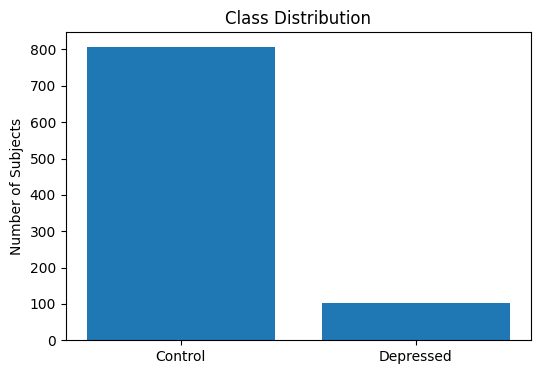

In [5]:
plt.figure(figsize=(6,4))

plt.bar(
    label_df["Class"],
    label_df["Count"]
)

plt.title("Class Distribution")

plt.ylabel("Number of Subjects")

plt.show()

In [8]:
# Explore one subject's data
sample = json_files[0]

with open(sample, encoding="utf-8") as f:
    data = json.load(f)

type(data)

list

In [13]:
len(data)

58

In [14]:
type(data[0])

dict

In [ ]:
# Dataset stats 
sample = json_files[0]

with open(sample, encoding="utf-8") as f:
    data = json.load(f)

print(type(data))
print(len(data))
print(type(data[0]))
data[0]

In [17]:
# how much each user's interaction come from own vs replies from others 
from collections import Counter

submission_count = []
target_comment_count = []
other_comment_count = []

for file in json_files:

    with open(file, encoding="utf-8") as f:
        timeline = json.load(f)

    submission_count.append(len(timeline))

    target = 0
    others = 0

    for event in timeline:

        for comment in event["comments"]:

            if comment["target"]:
                target += 1
            else:
                others += 1

    target_comment_count.append(target)
    other_comment_count.append(others)

print(f"Average submissions: {np.mean(submission_count):.2f}")
print(f"Average target comments: {np.mean(target_comment_count):.2f}")
print(f"Average other comments: {np.mean(other_comment_count):.2f}")

Average submissions: 306.49
Average target comments: 341.02
Average other comments: 13988.17


In [18]:
word_counts = []

for file in json_files:

    with open(file, encoding="utf-8") as f:
        timeline = json.load(f)

    words = 0

    for event in timeline:

        submission = event["submission"]

        title = submission.get("title", "")
        body = submission.get("body", "")

        words += len((title + " " + body).split())

        for comment in event["comments"]:

            if comment["target"]:

                words += len(comment.get("body", "").split())

    word_counts.append(words)

print(f"Average words per subject : {np.mean(word_counts):.0f}")
print(f"Median words per subject  : {np.median(word_counts):.0f}")
print(f"Maximum words per subject : {np.max(word_counts):.0f}")
print(f"Minimum words per subject : {np.min(word_counts):.0f}")

Average words per subject : 24115
Median words per subject  : 12283
Maximum words per subject : 263841
Minimum words per subject : 65
